<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,Input,Output
0,1.000000,14.967142
1,1.183673,10.187953
2,1.367347,19.820492
3,1.551020,30.549332
4,1.734694,15.155343
5,1.918367,17.535765
6,2.102041,38.251937
7,2.285714,32.919245
8,2.469388,23.537659
9,2.653061,36.847924



Training Samples: 40
Testing Samples: 10

========== MODEL PERFORMANCE ==========

LINEAR REGRESSION
MSE: 680.94
R2 Score: 0.9173

POLYNOMIAL REGRESSION
MSE: 71.87
R2 Score: 0.9913

========== COMPARISON TABLE ==========


,Model,MSE,R2 Score
0,Linear Regression,680.935051,0.917318
1,Polynomial Regression,71.874611,0.991273


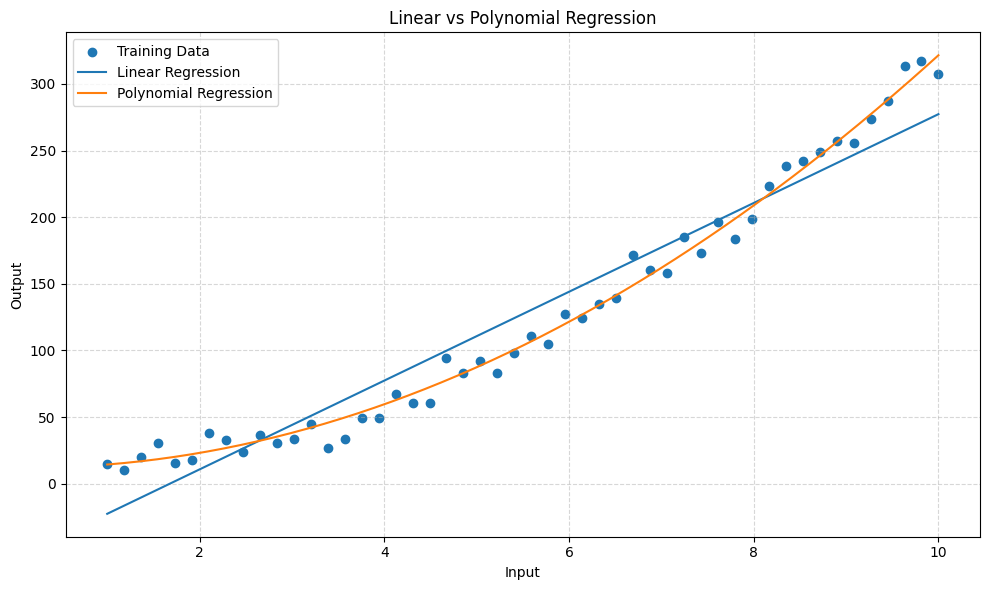

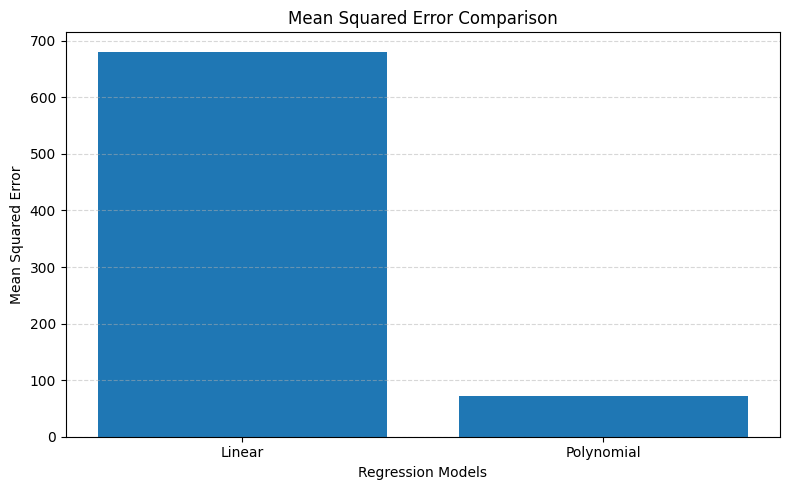

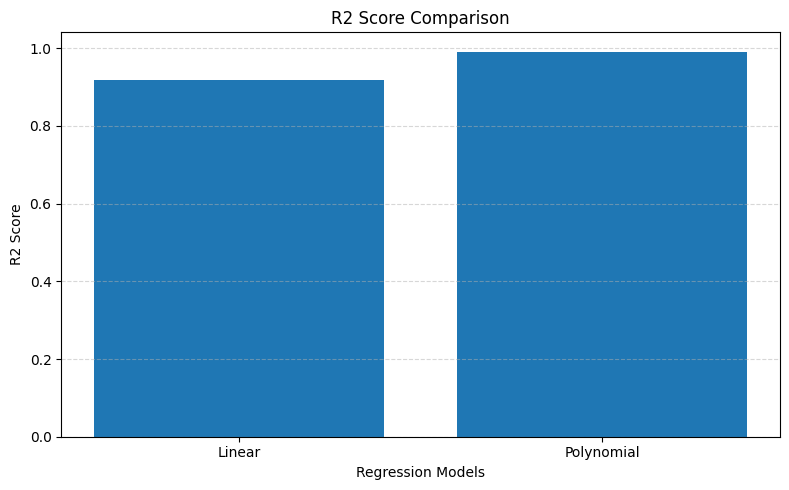

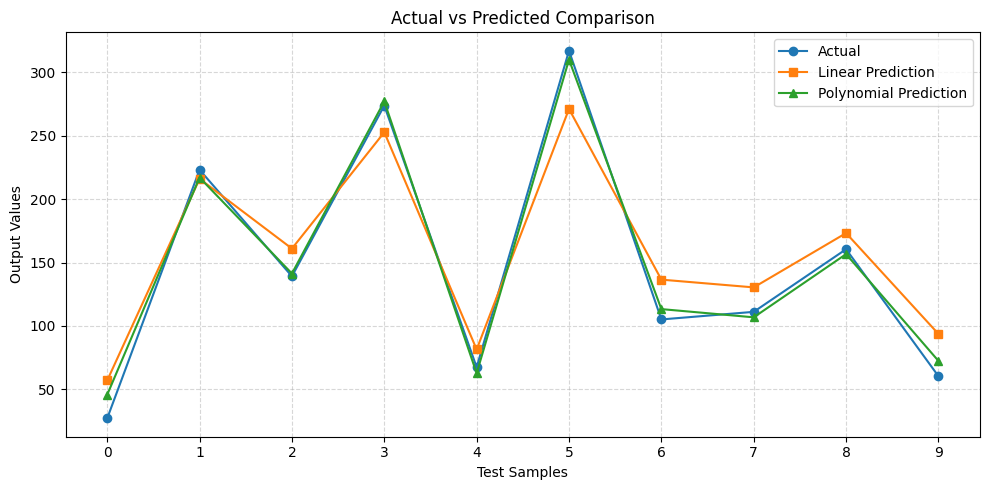


========== FINAL RESULT ==========
Polynomial Regression performs better.

Linear Regression R2 Score: 0.9173
Polynomial Regression R2 Score: 0.9913

Both Regression Models Implemented Successfully.


In [1]:
# EXPERIMENT 9: LINEAR VS POLYNOMIAL REGRESSION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# STEP 1: CREATE TRAINING DATASET

np.random.seed(42)

X = np.linspace(1, 10, 50).reshape(-1, 1)

y = 3 * X.flatten()**2 + 2 * X.flatten() + 5
y = y + np.random.normal(0, 10, 50)

df = pd.DataFrame({
    'Input': X.flatten(),
    'Output': y
})

print("========== TRAINING DATASET ==========")
display(df.head(10))

# STEP 2: SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: LINEAR REGRESSION MODEL

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

# STEP 4: POLYNOMIAL REGRESSION MODEL

poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

# STEP 5: EVALUATE MODELS

linear_mse = mean_squared_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)

poly_mse = mean_squared_error(y_test, poly_pred)
poly_r2 = r2_score(y_test, poly_pred)

print("\n========== MODEL PERFORMANCE ==========")

print("\nLINEAR REGRESSION")
print("MSE:", round(linear_mse, 2))
print("R2 Score:", round(linear_r2, 4))

print("\nPOLYNOMIAL REGRESSION")
print("MSE:", round(poly_mse, 2))
print("R2 Score:", round(poly_r2, 4))

# STEP 6: COMPARISON TABLE

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression'],
    'MSE': [linear_mse, poly_mse],
    'R2 Score': [linear_r2, poly_r2]
})

print("\n========== COMPARISON TABLE ==========")
display(comparison)

# STEP 7: PLOT TRAINING DATA AND REGRESSION LINES

X_curve = np.linspace(
    X.min(),
    X.max(),
    200
).reshape(-1, 1)

linear_curve = linear_model.predict(X_curve)
poly_curve = poly_model.predict(X_curve)

plt.figure(figsize=(10, 6))

plt.scatter(
    X,
    y,
    label='Training Data'
)

plt.plot(
    X_curve,
    linear_curve,
    label='Linear Regression'
)

plt.plot(
    X_curve,
    poly_curve,
    label='Polynomial Regression'
)

plt.title("Linear vs Polynomial Regression")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 8: MSE COMPARISON BAR GRAPH

plt.figure(figsize=(8, 5))

plt.bar(
    ['Linear', 'Polynomial'],
    [linear_mse, poly_mse]
)

plt.title("Mean Squared Error Comparison")
plt.xlabel("Regression Models")
plt.ylabel("Mean Squared Error")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 9: R2 SCORE COMPARISON GRAPH

plt.figure(figsize=(8, 5))

plt.bar(
    ['Linear', 'Polynomial'],
    [linear_r2, poly_r2]
)

plt.title("R2 Score Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 10: ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(10, 5))

sample_count = min(10, len(y_test))
index = np.arange(sample_count)

plt.plot(
    index,
    y_test[:sample_count],
    marker='o',
    label='Actual'
)

plt.plot(
    index,
    linear_pred[:sample_count],
    marker='s',
    label='Linear Prediction'
)

plt.plot(
    index,
    poly_pred[:sample_count],
    marker='^',
    label='Polynomial Prediction'
)

plt.title("Actual vs Predicted Comparison")
plt.xlabel("Test Samples")
plt.ylabel("Output Values")
plt.xticks(index)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: FINAL MODEL COMPARISON

print("\n========== FINAL RESULT ==========")

if poly_r2 > linear_r2:
    print("Polynomial Regression performs better.")
else:
    print("Linear Regression performs better.")

print("\nLinear Regression R2 Score:", round(linear_r2, 4))
print("Polynomial Regression R2 Score:", round(poly_r2, 4))

print("\nBoth Regression Models Implemented Successfully.")